# Online Retail: Sales and Repeat Purchasing

## Project overview

This project examines sales performance, cancellations, and customer
purchasing patterns using the UCI Online Retail dataset, covering
December 1, 2010–December 9, 2011.

### Business questions
- How do net product candidate sales vary over time and across markets?
- How do cancellations affect sales and product rankings?
- Is first-day spending associated with purchasing again the next month?

### Workflow
Excel was used for initial exploration and reconciliation.
SQLite provides reusable cleaning and analysis views.
Python validates the exported results, creates charts, and investigates
customer purchasing patterns.

### Scope
Product classification is preliminary. Repeated records remain in the
baseline, with their impact assessed separately. Customer purchasing
measures include purchases that may later have been cancelled.

Source: UCI Machine Learning Repository — Online Retail  
https://doi.org/10.24432/C5BW33

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

print("Working folder:", Path.cwd())
print("CSV files:", [file.name for file in Path.cwd().glob("*.csv")])

Working folder: /Users/r.dangol/Documents/Data_Analysis
CSV files: ['online_retail_raw.csv', 'cohort_next_month_repeat.csv', 'monthly_net_sales.csv']


In [2]:
monthly_sales = pd.read_csv("monthly_net_sales.csv")
cohort_repeat = pd.read_csv("cohort_next_month_repeat.csv")

print("Monthly Sales:", monthly_sales.shape)
display(monthly_sales.head())

print("Cohort Repeat Purchasing:", cohort_repeat.shape)
display(cohort_repeat.head())


Monthly Sales: (13, 2)


,sales_month,net_sales
0,2010-12,721692.47
1,2011-01,547274.38
2,2011-02,489139.53
3,2011-03,670305.72
4,2011-04,483422.88


Cohort Repeat Purchasing: (11, 4)


,cohort_month,cohort_customers,returned_next_month,next_month_repeat_pct
0,2010-12,884,323,36.54
1,2011-01,416,91,21.88
2,2011-02,380,71,18.68
3,2011-03,452,67,14.82
4,2011-04,300,63,21.00


In [3]:
monthly_sales = pd.read_csv("monthly_net_sales.csv")

monthly_sales["sales_month"] = pd.to_datetime(
    monthly_sales["sales_month"],
    format="%Y-%m",
    errors="raise"
)

monthly_sales["net_sales"] = pd.to_numeric(
    monthly_sales["net_sales"],
    errors="raise"
)

monthly_sales = monthly_sales.sort_values("sales_month")

display(monthly_sales.head())                                        


print(f"Net candidate sales: £{monthly_sales['net_sales'].sum():,.2f}")
print("Missing values:")
print(monthly_sales.isna().sum())

,sales_month,net_sales
0,2010-12-01,721692.47
1,2011-01-01,547274.38
2,2011-02-01,489139.53
3,2011-03-01,670305.72
4,2011-04-01,483422.88


Net candidate sales: £9,567,877.37
Missing values:
sales_month    0
net_sales      0
dtype: int64


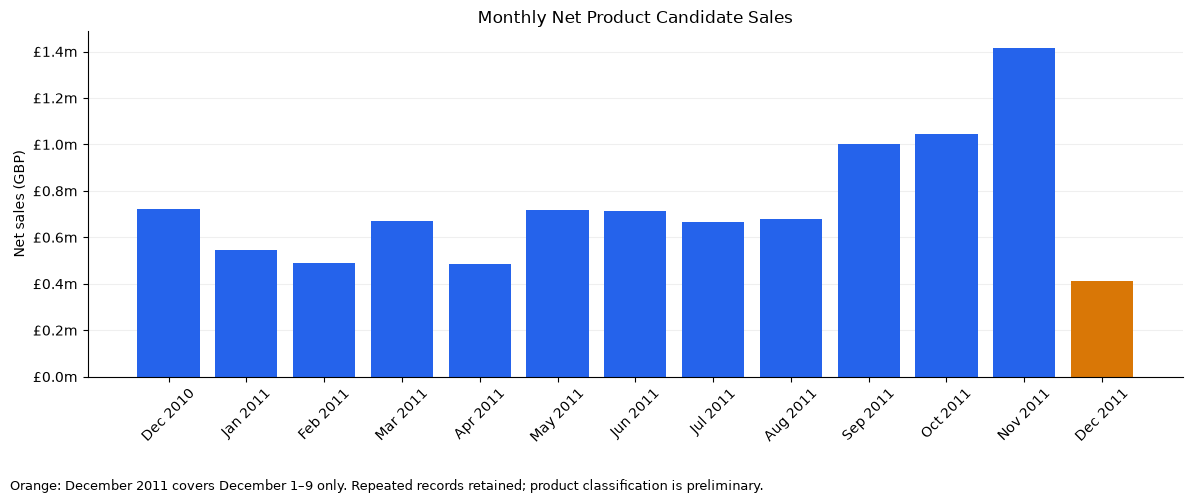

In [4]:
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 5))

colors = [
    "#D97706" if month == pd.Timestamp("2011-12-01")
    else "#2563EB"
    for month in monthly_sales["sales_month"]
]

ax.bar(
    monthly_sales["sales_month"].dt.strftime("%b %Y"),
    monthly_sales["net_sales"],
    color=colors
)

ax.set_title("Monthly Net Product Candidate Sales")
ax.set_ylabel("Net sales (GBP)")
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"£{value / 1_000_000:.1f}m")
)
ax.tick_params(axis="x", rotation=45)

ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.01, 0.01,
    "Orange: December 2011 covers December 1–9 only. "
    "Repeated records retained; product classification is preliminary.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.07, 1, 1])

Path("charts").mkdir(exist_ok=True)
fig.savefig("charts/monthly_net_sales.png", dpi=200, bbox_inches="tight")
plt.show()

### Monthly sales findings

- Net product candidate sales total £9,567,877.37.
- November 2011 recorded the highest monthly value at £1,416,244.38,
  up 35.28% from October.
- December 2011 includes only December 1–9, so its lower total
  should not be interpreted as a full-month decline.

These preliminary results include repeated records.
Product-code classification remains subject to further review.

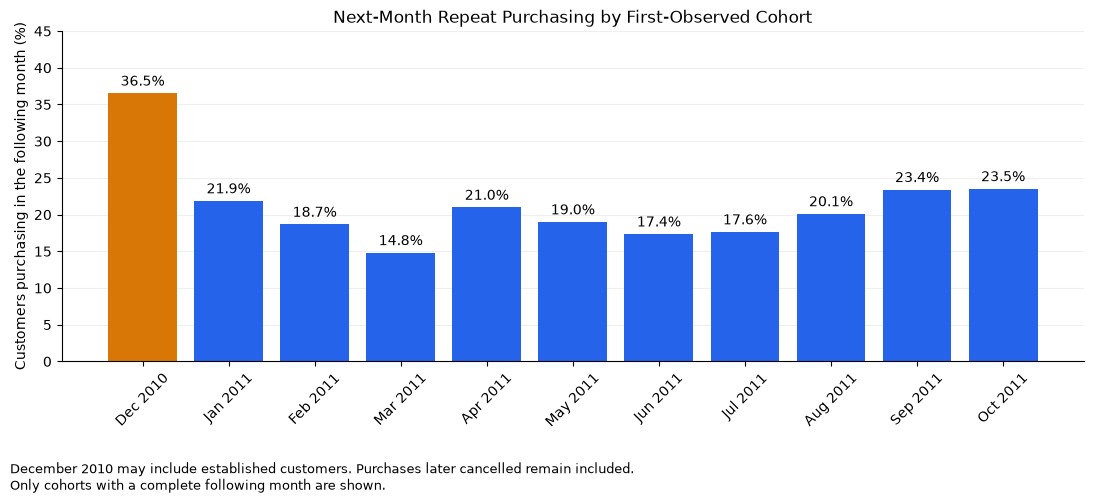

In [5]:
cohort_repeat["cohort_month"] = pd.to_datetime(
    cohort_repeat["cohort_month"],
    format="%Y-%m"
)

cohort_repeat = cohort_repeat.sort_values("cohort_month")

fig, ax = plt.subplots(figsize=(11, 5))

colors = [
    "#D97706" if month == pd.Timestamp("2010-12-01")
    else "#2563EB"
    for month in cohort_repeat["cohort_month"]
]

bars = ax.bar(
    cohort_repeat["cohort_month"].dt.strftime("%b %Y"),
    cohort_repeat["next_month_repeat_pct"],
    color=colors
)

ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title("Next-Month Repeat Purchasing by First-Observed Cohort")
ax.set_ylabel("Customers purchasing in the following month (%)")
ax.set_ylim(0, 45)
ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.01, 0.01,
    "December 2010 may include established customers. "
    "Purchases later cancelled remain included.\n"
    "Only cohorts with a complete following month are shown.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
fig.savefig("charts/cohort_next_month_repeat.png",
            dpi=200, bbox_inches="tight")
plt.show()

### Next-month repeat purchasing

- Of 884 customers first observed in December 2010, 323 purchased
  again in January 2011: 36.54%.
- For January–October 2011 cohorts, next-month repeat purchasing
  ranged from 14.82% to 23.53%.
- December's higher rate does not establish better customer acquisition.
  That cohort may include existing customers whose earlier purchases
  occurred before the dataset began.

Only cohorts with a complete following month are compared.
Purchases later cancelled are still included.

Business implication: investigate differences in product mix and
customer characteristics between cohorts before recommending changes
to customer follow-up campaigns.

In [6]:
from pathlib import Path

db_path = Path("retail_analysis.db")

print("Database location:", db_path.resolve())
print("Database found:", db_path.is_file())

Database location: /Users/r.dangol/Documents/Data_Analysis/retail_analysis.db
Database found: True


In [7]:
import sqlite3

connection = sqlite3.connect(
    db_path.resolve().as_uri() + "?mode=ro",
    uri=True
)

views = pd.read_sql_query(
    """
    SELECT name AS view_name
    FROM sqlite_master
    WHERE type = 'view'
    ORDER BY name;
    """,
    connection
)

display(views)

,view_name
0,cohort_next_month_repeat
1,customer_cohorts
2,customer_purchase_months
3,monthly_net_sales
4,net_product_candidates
5,retail_dates
6,retail_distinct
7,retail_source


In [8]:
monthly_db = pd.read_sql_query(
    "SELECT * FROM monthly_net_sales ORDER BY sales_month;",
    connection
)

cohort_db = pd.read_sql_query(
    "SELECT * FROM cohort_next_month_repeat ORDER BY cohort_month;",
    connection
)

monthly_csv = pd.read_csv("monthly_net_sales.csv")
cohort_csv = pd.read_csv("cohort_next_month_repeat.csv")

pd.testing.assert_frame_equal(
    monthly_db.reset_index(drop=True),
    monthly_csv.sort_values("sales_month").reset_index(drop=True),
    check_dtype=False,
    check_exact=False,
    rtol=0,
    atol=0.000001
)

pd.testing.assert_frame_equal(
    cohort_db.reset_index(drop=True),
    cohort_csv.sort_values("cohort_month").reset_index(drop=True),
    check_dtype=False,
    check_exact=False,
    rtol=0,
    atol=0.000001
)

print("Both database results match the CSV exports.")

Both database results match the CSV exports.


In [9]:
monthly_sales = monthly_db.copy()
cohort_repeat = cohort_db.copy()

monthly_sales["sales_month"] = pd.to_datetime(
    monthly_sales["sales_month"],
    format="%Y-%m"
)

cohort_repeat["cohort_month"] = pd.to_datetime(
    cohort_repeat["cohort_month"],
    format="%Y-%m"
)

print("Chart data loaded from SQLite.")

Chart data loaded from SQLite.


In [10]:
transactions = pd.read_sql_query(
    """
    SELECT
        p.InvoiceNo,
        p.CustomerID,
        p.Quantity,
        p.LineAmount,
        d.invoice_day
    FROM net_product_candidates AS p
    JOIN retail_dates AS d
        ON p.InvoiceDate = d.InvoiceDate
    WHERE p.CustomerID IS NOT NULL
      AND TRIM(p.CustomerID) <> '';
    """,
    connection
)

transactions["invoice_day"] = pd.to_datetime(
    transactions["invoice_day"],
    format="%Y-%m-%d"
)

print(f"Transaction lines: {len(transactions):,}")
print(f"Net sales: £{transactions['LineAmount'].sum():,.2f}")
display(transactions.head())

Transaction lines: 405,029
Net sales: £8,285,365.89


,InvoiceNo,CustomerID,Quantity,LineAmount,invoice_day
0,536365,17850,6.0,15.30,2010-12-01
1,536365,17850,6.0,20.34,2010-12-01
2,536365,17850,8.0,22.00,2010-12-01
3,536365,17850,6.0,20.34,2010-12-01
4,536365,17850,6.0,20.34,2010-12-01


In [11]:
positive_lines = transactions.loc[
    (transactions["Quantity"] > 0)
    & ~transactions["InvoiceNo"].astype(str).str.upper().str.startswith("C")
].copy()

orders = (
    positive_lines
    .groupby(["CustomerID", "InvoiceNo"], as_index=False)
    .agg(
        purchase_date=("invoice_day", "min"),
        positive_order_value=("LineAmount", "sum")
    )
)

print(f"Purchase invoices: {len(orders):,}")
print(f"Purchasing customers: {orders['CustomerID'].nunique():,}")
display(orders.head())

Purchase invoices: 18,405
Purchasing customers: 4,334


,CustomerID,InvoiceNo,purchase_date,positive_order_value
0,12346,541431,2011-01-18,77183.60
1,12347,537626,2010-12-07,711.79
2,12347,542237,2011-01-26,475.39
3,12347,549222,2011-04-07,636.25
4,12347,556201,2011-06-09,382.52


In [12]:
customer_days = (
    orders.groupby(["CustomerID", "purchase_date"], as_index=False)
    .agg(first_day_value=("positive_order_value", "sum"))
)

first_purchases = (
    customer_days
    .sort_values(["CustomerID", "purchase_date"])
    .drop_duplicates("CustomerID")
    .rename(columns={"purchase_date": "first_purchase_date"})
)

# Exclude the initial cohort and cohorts without a complete next month.
eligible_customers = first_purchases.loc[
    (first_purchases["first_purchase_date"] >= "2011-01-01")
    & (first_purchases["first_purchase_date"] < "2011-11-01")
].copy()

print(f"Eligible customers: {len(eligible_customers):,}")
display(eligible_customers.head())

Eligible customers: 3,086


,CustomerID,first_purchase_date,first_day_value
0,12346,2011-01-18,77183.6
13,12350,2011-02-02,294.4
14,12352,2011-02-16,296.5
21,12353,2011-05-19,89.0
22,12354,2011-04-21,1079.4


In [13]:
purchase_months = orders.assign(
    purchase_month=orders["purchase_date"].dt.to_period("M")
)[["CustomerID", "purchase_month"]].drop_duplicates()

eligible_customers["next_month"] = (
    eligible_customers["first_purchase_date"].dt.to_period("M") + 1
)

eligible_customers = eligible_customers.merge(
    purchase_months.assign(returned_next_month=True),
    left_on=["CustomerID", "next_month"],
    right_on=["CustomerID", "purchase_month"],
    how="left",
    validate="one_to_one"
)

eligible_customers["returned_next_month"] = (
    eligible_customers["returned_next_month"].eq(True)
)

print(f"Customers: {len(eligible_customers):,}")
print(
    "Returned next month:",
    eligible_customers["returned_next_month"].sum()
)
print(
    f"Repeat share: "
    f"{eligible_customers['returned_next_month'].mean():.2%}"
)

Customers: 3,086
Returned next month: 609
Repeat share: 19.73%


In [14]:
spend_analysis = eligible_customers[
    ["CustomerID", "first_day_value", "returned_next_month"]
].copy()

spend_analysis["spend_group"] = pd.qcut(
    spend_analysis["first_day_value"],
    q=4,
    duplicates="drop"
)

spend_summary = (
    spend_analysis
    .groupby("spend_group", observed=True)
    .agg(
        customers=("CustomerID", "size"),
        min_first_day_spend=("first_day_value", "min"),
        max_first_day_spend=("first_day_value", "max"),
        returning_customers=("returned_next_month", "sum"),
        repeat_share=("returned_next_month", "mean")
    )
    .reset_index()
)

spend_summary["repeat_pct"] = (
    100 * spend_summary.pop("repeat_share")
)

display(spend_summary.round(2))

,spend_group,customers,min_first_day_spend,max_first_day_spend,returning_customers,repeat_pct
0,"(0.849, 167.368]",772,0.85,167.36,125,16.19
1,"(167.368, 304.225]",771,167.39,304.21,134,17.38
2,"(304.225, 469.195]",771,304.24,469.18,168,21.79
3,"(469.195, 77183.6]",772,469.20,77183.60,182,23.58


In [15]:
largest_first_purchase = eligible_customers.nlargest(
    1, "first_day_value"
)

display(
    largest_first_purchase[
        ["CustomerID", "first_purchase_date",
         "first_day_value", "returned_next_month"]
    ]
)

customer_id = largest_first_purchase["CustomerID"].iloc[0]

display(
    transactions.loc[
        transactions["CustomerID"] == customer_id
    ].sort_values(["invoice_day", "InvoiceNo"])
)

,CustomerID,first_purchase_date,first_day_value,returned_next_month
0,12346,2011-01-18,77183.6,False


,InvoiceNo,CustomerID,Quantity,LineAmount,invoice_day
37954,541431,12346,74215.0,77183.6,2011-01-18
37959,C541433,12346,-74215.0,-77183.6,2011-01-18


In [16]:
sensitivity = (
    spend_analysis.loc[
        spend_analysis["CustomerID"] != customer_id
    ]
    .groupby("spend_group", observed=True)
    .agg(
        customers=("CustomerID", "size"),
        returning_customers=("returned_next_month", "sum"),
        repeat_share=("returned_next_month", "mean")
    )
    .reset_index()
)

sensitivity["repeat_pct"] = 100 * sensitivity.pop("repeat_share")

display(sensitivity.round(2))


,spend_group,customers,returning_customers,repeat_pct
0,"(0.849, 167.368]",772,125,16.19
1,"(167.368, 304.225]",771,134,17.38
2,"(304.225, 469.195]",771,168,21.79
3,"(469.195, 77183.6]",771,182,23.61


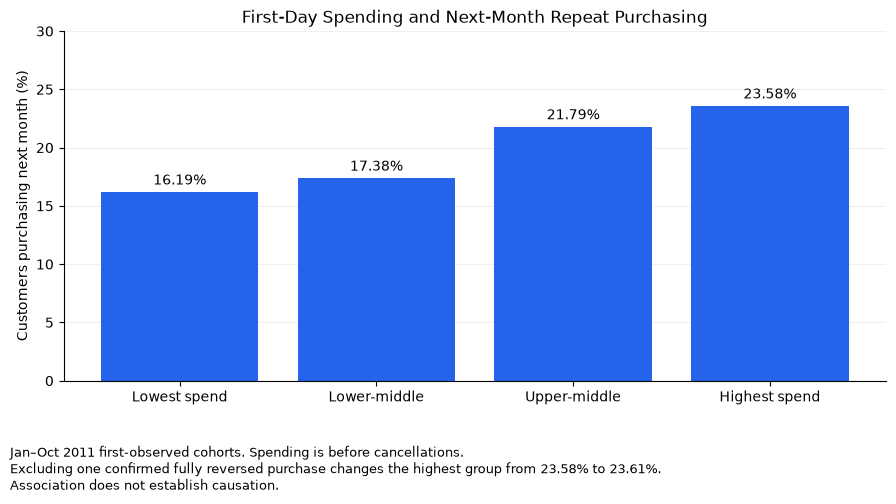

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

labels = ["Lowest spend", "Lower-middle", "Upper-middle", "Highest spend"]

bars = ax.bar(
    labels,
    spend_summary["repeat_pct"],
    color="#2563EB"
)

ax.bar_label(bars, fmt="%.2f%%", padding=3)
ax.set_ylim(0, 30)
ax.set_ylabel("Customers purchasing next month (%)")
ax.set_title("First-Day Spending and Next-Month Repeat Purchasing")
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.01, 0.01,
    "Jan–Oct 2011 first-observed cohorts. Spending is before cancellations.\n"
    "Excluding one confirmed fully reversed purchase changes the highest "
    "group from 23.58% to 23.61%.\n"
    "Association does not establish causation.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.15, 1, 1])
fig.savefig(
    "charts/first_day_spend_repeat.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

### First-day spending and repeat purchasing

Among 3,086 customers first observed during January–October 2011,
next-month repeat purchasing increased across four first-day spending
groups, from 16.19% in the lowest group to 23.58% in the highest.

The difference was 7.39 percentage points. Excluding one confirmed
fully reversed purchase changed the highest group's rate to 23.61%,
using the original group boundaries.

This association does not establish causation. Cohort timing,
customer type, and other cancellations may influence the results.
Spending is measured before cancellations, and repeated records remain.

Business implication: first-day spending is worth investigating as a
customer-segmentation variable. These results alone do not justify
targeting only high-spending customers.

In [18]:
cohort_spend = spend_analysis.merge(
    eligible_customers[["CustomerID", "first_purchase_date"]],
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

cohort_spend["cohort_month"] = (
    cohort_spend["first_purchase_date"].dt.to_period("M").astype(str)
)

cohort_comparison = (
    cohort_spend
    .groupby(["cohort_month", "spend_group"], observed=True)
    .agg(
        customers=("CustomerID", "size"),
        returning=("returned_next_month", "sum")
    )
    .reset_index()
)

cohort_comparison["repeat_pct"] = (
    100 * cohort_comparison["returning"]
    / cohort_comparison["customers"]
)

rates = cohort_comparison.pivot(
    index="cohort_month",
    columns="spend_group",
    values="repeat_pct"
)

counts = cohort_comparison.pivot(
    index="cohort_month",
    columns="spend_group",
    values="customers"
)

print("Next-month repeat purchasing (%):")
display(rates.round(1))

print("Customers in each group:")
display(counts)

Next-month repeat purchasing (%):


spend_group,"(0.849, 167.368]","(167.368, 304.225]","(304.225, 469.195]","(469.195, 77183.6]"
cohort_month,,,,
2011-01,18.9,19.1,31.6,18.6
2011-02,12.9,20.9,19.4,22.1
2011-03,11.8,10.3,14.9,22.3
2011-04,17.6,11.7,18.8,37.7
2011-05,19.4,19.4,18.7,18.5
2011-06,16.9,13.2,21.4,18.0
2011-07,11.1,23.9,18.2,18.6
2011-08,21.3,13.6,30.3,17.8
2011-09,17.3,20.6,22.8,29.0


Customers in each group:


spend_group,"(0.849, 167.368]","(167.368, 304.225]","(304.225, 469.195]","(469.195, 77183.6]"
cohort_month,,,,
2011-01,106,110,98,102
2011-02,101,86,98,95
2011-03,110,116,114,112
2011-04,74,77,80,69
2011-05,72,72,75,65
2011-06,83,53,56,50
2011-07,54,46,44,43
2011-08,47,44,33,45
2011-09,52,68,79,100


In [19]:
# Use each month's share of all eligible customers as a common weight.
cohort_weights = counts.sum(axis=1) / counts.to_numpy().sum()

# Calculate from unrounded rates.
adjusted_rates = rates.mul(cohort_weights, axis=0).sum(axis=0)

comparison = pd.DataFrame({
    "original_repeat_pct": spend_summary.set_index(
        "spend_group"
    )["repeat_pct"],
    "cohort_adjusted_repeat_pct": adjusted_rates
})

display(comparison.round(2))

,original_repeat_pct,cohort_adjusted_repeat_pct
spend_group,,
"(0.849, 167.368]",16.19,16.25
"(167.368, 304.225]",17.38,17.39
"(304.225, 469.195]",21.79,21.98
"(469.195, 77183.6]",23.58,23.36


In [20]:
Path("outputs").mkdir(exist_ok=True)

spend_summary.to_csv(
    "outputs/first_day_spend_repeat.csv", index=False
)
cohort_comparison.to_csv(
    "outputs/spend_repeat_by_cohort.csv", index=False
)
comparison.to_csv(
    "outputs/cohort_adjusted_repeat.csv", index=True
)

print("Three analysis tables saved.")

Three analysis tables saved.


In [21]:
country_sales = pd.read_sql_query(
    """
    SELECT
        Country,
        SUM(LineAmount) AS net_sales
    FROM net_product_candidates
    GROUP BY Country
    ORDER BY net_sales DESC;
    """,
    connection
)

Path("outputs").mkdir(exist_ok=True)
country_sales.to_csv("outputs/country_net_sales.csv", index=False)

display(country_sales.head(3))

,Country,net_sales
0,United Kingdom,8071375.773
1,Netherlands,283479.540
2,EIRE,264838.460


## Findings and limitations

### Main findings
- Net product candidate sales total £9,567,877.37.
- The UK contributes 84.36% of that value.
- November 2011 has the highest monthly net sales at £1,416,244.38.
- Cancellation value offsets 7.04% of positive product candidate sales.
- Among January–October 2011 first-observed cohorts, higher first-day
  spending is associated with higher next-month repeat purchasing.
  After adjusting for cohort composition, rates range from 16.25%
  in the lowest spending group to 23.36% in the highest.

### Business implications
- Monitor cancellations alongside positive sales: a large reversed
  transaction can produce a misleading bestseller ranking.
- Investigate dependence on the UK market before proposing expansion.
- Evaluate first-day spending as a segmentation variable in a measured
  customer follow-up experiment, rather than assuming it causes loyalty.

### Limitations
- December 2011 contains only nine days of observations.
- First observed purchases are not necessarily first-ever purchases.
- Customer activity measures include purchases later cancelled.
- Baseline totals retain repeated records. Excluding repeated product
  rows reduces net candidate sales by £21,380.98, about 0.22%.
- Unmapped product codes remain candidates pending further review.
- Observational associations do not establish causation.